In [1]:
print("Python is working!")


Python is working!


In [10]:
# ============================================================
# UAC PROJECT - COMPLETE DATA ANALYSIS
# System Capacity & Care Load Analytics for Unaccompanied Children
# ============================================================

import pandas as pd
import numpy as np

print("=" * 70)
print("UAC SYSTEM CAPACITY & CARE LOAD ANALYTICS")
print("=" * 70)


# ============================================================
# STEP 1 - LOAD DATA
# ============================================================

df = pd.read_csv("../data/uac_data.csv")

print("\nDATASET LOADED")
print("-" * 50)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])


# ============================================================
# STEP 2 - CLEAN COLUMN NAMES
# ============================================================

df.columns = df.columns.str.strip()


# ============================================================
# STEP 3 - CONVERT DATE
# ============================================================

df["Date"] = pd.to_datetime(
    df["Date"],
    errors="coerce"
)


# ============================================================
# STEP 4 - CLEAN NUMERIC DATA
# ============================================================

numeric_columns = [
    "Children apprehended and placed in CBP custody*",
    "Children in CBP custody",
    "Children transferred out of CBP custody",
    "Children in HHS Care",
    "Children discharged from HHS Care"
]

for column in numeric_columns:

    df[column] = (
        df[column]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.replace('"', "", regex=False)
        .str.strip()
    )

    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )


# ============================================================
# STEP 5 - REMOVE INVALID DATES
# ============================================================

invalid_dates = df["Date"].isna().sum()

print("\nInvalid dates:", invalid_dates)

df = df.dropna(
    subset=["Date"]
)


# ============================================================
# STEP 6 - SORT DATA
# ============================================================

df = df.sort_values(
    "Date"
).reset_index(drop=True)


# ============================================================
# STEP 7 - REMOVE DUPLICATE DATES
# ============================================================

duplicate_dates = df["Date"].duplicated().sum()

print("Duplicate dates:", duplicate_dates)

df = df.drop_duplicates(
    subset=["Date"],
    keep="first"
).reset_index(drop=True)


# ============================================================
# STEP 8 - MISSING VALUE CHECK
# ============================================================

print("\nMISSING VALUES")
print("-" * 50)

print(
    df.isnull().sum()
)


# ============================================================
# STEP 9 - VALIDATION FLAGS
# ============================================================

df["transfer_gt_cbp_flag"] = (
    df["Children transferred out of CBP custody"]
    >
    df["Children in CBP custody"]
)

df["discharge_gt_hhs_flag"] = (
    df["Children discharged from HHS Care"]
    >
    df["Children in HHS Care"]
)


print("\nVALIDATION")
print("-" * 50)

print(
    "Transfer greater than CBP custody:",
    df["transfer_gt_cbp_flag"].sum()
)

print(
    "Discharge greater than HHS care:",
    df["discharge_gt_hhs_flag"].sum()
)


# ============================================================
# STEP 10 - TOTAL SYSTEM LOAD
# ============================================================

df["Total System Load"] = (
    df["Children in CBP custody"]
    +
    df["Children in HHS Care"]
)


# ============================================================
# STEP 11 - NET INTAKE PRESSURE
# ============================================================

df["Net Intake Pressure"] = (
    df["Children transferred out of CBP custody"]
    -
    df["Children discharged from HHS Care"]
)


# ============================================================
# STEP 12 - CARE LOAD GROWTH RATE
# ============================================================

df["Care Load Growth Rate"] = (
    df["Total System Load"]
    .pct_change()
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    * 100
)


# ============================================================
# STEP 13 - DISCHARGE OFFSET RATIO
# ============================================================

df["Discharge Offset Ratio"] = np.where(

    df["Children transferred out of CBP custody"] > 0,

    df["Children discharged from HHS Care"]
    /
    df["Children transferred out of CBP custody"],

    np.nan
)


# ============================================================
# STEP 14 - ROLLING LOAD AVERAGES
# ============================================================

df["7_Observation_Load_Avg"] = (
    df["Total System Load"]
    .rolling(
        window=7,
        min_periods=1
    )
    .mean()
)

df["14_Observation_Load_Avg"] = (
    df["Total System Load"]
    .rolling(
        window=14,
        min_periods=1
    )
    .mean()
)


# ============================================================
# STEP 15 - MONTH AND WEEK
# ============================================================

df["Month"] = (
    df["Date"]
    .dt.to_period("M")
    .astype(str)
)

df["Week"] = (
    df["Date"]
    .dt.isocalendar()
    .week
    .astype(int)
)


# ============================================================
# STEP 16 - HIGH LOAD FLAG
# ============================================================

load_threshold = (
    df["Total System Load"]
    .quantile(0.75)
)

df["High_Load_Flag"] = (
    df["Total System Load"]
    >=
    load_threshold
)

df["High_Load_Group"] = np.where(
    df["High_Load_Flag"],
    "High Load",
    "Normal Load"
)


# ============================================================
# STEP 17 - CUMULATIVE NET INTAKE
# ============================================================

df["Cumulative Net Intake"] = (
    df["Net Intake Pressure"]
    .fillna(0)
    .cumsum()
)


# ============================================================
# STEP 18 - ROLLING INTAKE AVERAGES
# ============================================================

df["7_Observation_Intake_Avg"] = (
    df["Net Intake Pressure"]
    .rolling(
        window=7,
        min_periods=1
    )
    .mean()
)

df["14_Observation_Intake_Avg"] = (
    df["Net Intake Pressure"]
    .rolling(
        window=14,
        min_periods=1
    )
    .mean()
)


# ============================================================
# STEP 19 - DATE GAP ANALYSIS
# ============================================================

date_gaps = (
    df["Date"]
    .diff()
    .dt.days
    .dropna()
)

print("\nDATE GAP ANALYSIS")
print("-" * 50)

print(
    "Average date gap:",
    round(date_gaps.mean(), 2),
    "days"
)

print(
    "Largest date gap:",
    round(date_gaps.max(), 2),
    "days"
)

print(
    "Gaps greater than 1 day:",
    (date_gaps > 1).sum()
)


# ============================================================
# STEP 20 - KPI CALCULATIONS
# ============================================================

average_system_load = (
    df["Total System Load"].mean()
)

maximum_system_load = (
    df["Total System Load"].max()
)

minimum_system_load = (
    df["Total System Load"].min()
)

average_net_intake = (
    df["Net Intake Pressure"].mean()
)

care_load_volatility = (
    df["Total System Load"].std()
)

backlog_accumulation_rate = (
    (df["Net Intake Pressure"] > 0).mean()
    * 100
)

total_transfers = (
    df["Children transferred out of CBP custody"]
    .sum()
)

total_discharges = (
    df["Children discharged from HHS Care"]
    .sum()
)

discharge_offset_ratio = (

    total_discharges
    /
    total_transfers

    if total_transfers > 0
    else np.nan
)


# ============================================================
# STEP 21 - CBP / HHS LOAD SHARE
# ============================================================

total_cbp = (
    df["Children in CBP custody"]
    .sum()
)

total_hhs = (
    df["Children in HHS Care"]
    .sum()
)

total_care = (
    total_cbp
    +
    total_hhs
)

cbp_share = (
    total_cbp / total_care * 100
)

hhs_share = (
    total_hhs / total_care * 100
)


# ============================================================
# STEP 22 - DISPLAY KPIs
# ============================================================

print("\n")
print("=" * 70)
print("KEY PERFORMANCE INDICATORS")
print("=" * 70)

print(
    "Average System Load:",
    round(average_system_load, 2)
)

print(
    "Maximum System Load:",
    round(maximum_system_load, 2)
)

print(
    "Minimum System Load:",
    round(minimum_system_load, 2)
)

print(
    "Average Net Intake Pressure:",
    round(average_net_intake, 2)
)

print(
    "Care Load Volatility Index:",
    round(care_load_volatility, 2)
)

print(
    "Backlog Accumulation Rate:",
    round(backlog_accumulation_rate, 2),
    "%"
)

print(
    "Discharge Offset Ratio:",
    round(discharge_offset_ratio, 4)
)

print(
    "CBP Load Share:",
    round(cbp_share, 2),
    "%"
)

print(
    "HHS Load Share:",
    round(hhs_share, 2),
    "%"
)


# ============================================================
# STEP 23 - TOP 10 SYSTEM LOAD DAYS
# ============================================================

top_load_days = (
    df[
        [
            "Date",
            "Total System Load",
            "Children in CBP custody",
            "Children in HHS Care"
        ]
    ]
    .sort_values(
        "Total System Load",
        ascending=False
    )
    .head(10)
)

print("\nTOP 10 SYSTEM LOAD DAYS")
print("-" * 50)

display(top_load_days)


# ============================================================
# STEP 24 - TOP 10 NET INTAKE DAYS
# ============================================================

top_intake_days = (
    df[
        [
            "Date",
            "Net Intake Pressure",
            "Children transferred out of CBP custody",
            "Children discharged from HHS Care"
        ]
    ]
    .sort_values(
        "Net Intake Pressure",
        ascending=False
    )
    .head(10)
)

print("\nTOP 10 NET INTAKE DAYS")
print("-" * 50)

display(top_intake_days)


# ============================================================
# STEP 25 - MONTHLY SUMMARY
# ============================================================

monthly_summary = (

    df
    .groupby("Month")
    .agg(

        Average_System_Load=(
            "Total System Load",
            "mean"
        ),

        Maximum_System_Load=(
            "Total System Load",
            "max"
        ),

        Average_Net_Intake=(
            "Net Intake Pressure",
            "mean"
        ),

        Total_Transfers=(
            "Children transferred out of CBP custody",
            "sum"
        ),

        Total_Discharges=(
            "Children discharged from HHS Care",
            "sum"
        )
    )
    .reset_index()
)


# ============================================================
# STEP 26 - SAVE FINAL DATA
# ============================================================

df.to_csv(
    "../data/uac_final_analysis.csv",
    index=False
)

monthly_summary.to_csv(
    "../data/uac_monthly_summary.csv",
    index=False
)


# ============================================================
# STEP 27 - FINAL OUTPUT
# ============================================================

print("\n")
print("=" * 70)
print("🎉 UAC DATA ANALYSIS COMPLETED SUCCESSFULLY!")
print("=" * 70)

print(
    "Final rows:",
    df.shape[0]
)

print(
    "Final columns:",
    df.shape[1]
)

print(
    "\nFinal analysis file:"
)

print(
    "../data/uac_final_analysis.csv"
)

print(
    "\nMonthly summary file:"
)

print(
    "../data/uac_monthly_summary.csv"
)

print("\nFinal columns:")

for number, column in enumerate(
    df.columns,
    1
):
    print(
        number,
        ".",
        column
    )

UAC SYSTEM CAPACITY & CARE LOAD ANALYTICS

DATASET LOADED
--------------------------------------------------
Rows: 1170
Columns: 6

Invalid dates: 450
Duplicate dates: 0

MISSING VALUES
--------------------------------------------------
Date                                               0
Children apprehended and placed in CBP custody*    0
Children in CBP custody                            0
Children transferred out of CBP custody            0
Children in HHS Care                               0
Children discharged from HHS Care                  0
dtype: int64

VALIDATION
--------------------------------------------------
Transfer greater than CBP custody: 86
Discharge greater than HHS care: 0

DATE GAP ANALYSIS
--------------------------------------------------
Average date gap: 1.49 days
Largest date gap: 10.0 days
Gaps greater than 1 day: 161


KEY PERFORMANCE INDICATORS
Average System Load: 6232.77
Maximum System Load: 11762.0
Minimum System Load: 2002.0
Average Net Intake Pressur

,Date,Total System Load,Children in CBP custody,Children in HHS Care
224,2023-12-20,11762.0,246.0,11516.0
225,2023-12-21,11603.0,228.0,11375.0
223,2023-12-19,11476.0,185.0,11291.0
220,2023-12-14,11399.0,157.0,11242.0
161,2023-09-19,11382.0,287.0,11095.0
162,2023-09-20,11374.0,310.0,11064.0
219,2023-12-13,11373.0,181.0,11192.0
163,2023-09-21,11352.0,285.0,11067.0
226,2023-12-25,11340.0,196.0,11144.0
222,2023-12-18,11337.0,188.0,11149.0



TOP 10 NET INTAKE DAYS
--------------------------------------------------


,Date,Net Intake Pressure,Children transferred out of CBP custody,Children discharged from HHS Care
259,2024-02-12,206.0,440.0,234.0
260,2024-02-13,189.0,349.0,160.0
309,2024-04-23,173.0,307.0,134.0
310,2024-04-24,153.0,307.0,154.0
263,2024-02-19,153.0,371.0,218.0
335,2024-05-30,149.0,339.0,190.0
255,2024-02-06,145.0,323.0,178.0
461,2024-12-03,135.0,242.0,107.0
391,2024-08-20,133.0,245.0,112.0
274,2024-03-05,131.0,345.0,214.0




🎉 UAC DATA ANALYSIS COMPLETED SUCCESSFULLY!
Final rows: 720
Final columns: 21

Final analysis file:
../data/uac_final_analysis.csv

Monthly summary file:
../data/uac_monthly_summary.csv

Final columns:
1 . Date
2 . Children apprehended and placed in CBP custody*
3 . Children in CBP custody
4 . Children transferred out of CBP custody
5 . Children in HHS Care
6 . Children discharged from HHS Care
7 . transfer_gt_cbp_flag
8 . discharge_gt_hhs_flag
9 . Total System Load
10 . Net Intake Pressure
11 . Care Load Growth Rate
12 . Discharge Offset Ratio
13 . 7_Observation_Load_Avg
14 . 14_Observation_Load_Avg
15 . Month
16 . Week
17 . High_Load_Flag
18 . High_Load_Group
19 . Cumulative Net Intake
20 . 7_Observation_Intake_Avg
21 . 14_Observation_Intake_Avg


In [11]:
print("DATASET VALIDATION")
print("=" * 50)

print("Rows:", len(df))
print("Columns:", len(df.columns))

print("\nDate range:")
print("Start:", df["Date"].min())
print("End:", df["Date"].max())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate dates:")
print(df["Date"].duplicated().sum())

print("\nNegative values:")

numeric_columns = [
    "Children apprehended and placed in CBP custody*",
    "Children in CBP custody",
    "Children transferred out of CBP custody",
    "Children in HHS Care",
    "Children discharged from HHS Care",
    "Total System Load",
    "Net Intake Pressure"
]

for column in numeric_columns:
    print(
        column,
        ":", 
        (df[column] < 0).sum()
    )

print("\nBasic statistics:")
print(
    df[
        [
            "Children in CBP custody",
            "Children in HHS Care",
            "Total System Load",
            "Net Intake Pressure"
        ]
    ].describe()
)

DATASET VALIDATION
Rows: 720
Columns: 21

Date range:
Start: 2023-01-12 00:00:00
End: 2025-12-21 00:00:00

Missing values:
Date                                               0
Children apprehended and placed in CBP custody*    0
Children in CBP custody                            0
Children transferred out of CBP custody            0
Children in HHS Care                               0
Children discharged from HHS Care                  0
transfer_gt_cbp_flag                               0
discharge_gt_hhs_flag                              0
Total System Load                                  0
Net Intake Pressure                                0
Care Load Growth Rate                              1
Discharge Offset Ratio                             3
7_Observation_Load_Avg                             0
14_Observation_Load_Avg                            0
Month                                              0
Week                                               0
High_Load_Flag               

In [12]:
print("KEY PROJECT FINDINGS")
print("=" * 60)

# 1. Highest system load
highest_load = df.loc[
    df["Total System Load"].idxmax()
]

print("\n1. HIGHEST SYSTEM LOAD")
print("Date:", highest_load["Date"].date())
print("Total System Load:", highest_load["Total System Load"])
print("CBP Custody:", highest_load["Children in CBP custody"])
print("HHS Care:", highest_load["Children in HHS Care"])


# 2. Lowest system load
lowest_load = df.loc[
    df["Total System Load"].idxmin()
]

print("\n2. LOWEST SYSTEM LOAD")
print("Date:", lowest_load["Date"].date())
print("Total System Load:", lowest_load["Total System Load"])
print("CBP Custody:", lowest_load["Children in CBP custody"])
print("HHS Care:", lowest_load["Children in HHS Care"])


# 3. Highest positive intake pressure
highest_intake = df.loc[
    df["Net Intake Pressure"].idxmax()
]

print("\n3. HIGHEST POSITIVE INTAKE PRESSURE")
print("Date:", highest_intake["Date"].date())
print("Net Intake Pressure:", highest_intake["Net Intake Pressure"])
print(
    "Transfers:",
    highest_intake["Children transferred out of CBP custody"]
)
print(
    "Discharges:",
    highest_intake["Children discharged from HHS Care"]
)


# 4. Most negative intake pressure
lowest_intake = df.loc[
    df["Net Intake Pressure"].idxmin()
]

print("\n4. MOST NEGATIVE INTAKE PRESSURE")
print("Date:", lowest_intake["Date"].date())
print("Net Intake Pressure:", lowest_intake["Net Intake Pressure"])
print(
    "Transfers:",
    lowest_intake["Children transferred out of CBP custody"]
)
print(
    "Discharges:",
    lowest_intake["Children discharged from HHS Care"]
)


# 5. Positive vs negative intake observations
positive_days = (
    df["Net Intake Pressure"] > 0
).sum()

zero_days = (
    df["Net Intake Pressure"] == 0
).sum()

negative_days = (
    df["Net Intake Pressure"] < 0
).sum()

print("\n5. INTAKE PRESSURE DISTRIBUTION")
print("Positive observations:", positive_days)
print("Zero observations:", zero_days)
print("Negative observations:", negative_days)


# 6. CBP and HHS averages
print("\n6. AVERAGE CARE LOAD")
print(
    "Average CBP Custody:",
    round(df["Children in CBP custody"].mean(), 2)
)

print(
    "Average HHS Care:",
    round(df["Children in HHS Care"].mean(), 2)
)

print(
    "Average Total System Load:",
    round(df["Total System Load"].mean(), 2)
)


# 7. Overall transfers and discharges
total_transfers = df[
    "Children transferred out of CBP custody"
].sum()

total_discharges = df[
    "Children discharged from HHS Care"
].sum()

print("\n7. TOTAL FLOWS")
print("Total Transfers:", total_transfers)
print("Total Discharges:", total_discharges)

print(
    "Overall Discharge-to-Transfer Ratio:",
    round(
        total_discharges / total_transfers,
        3
    )
    if total_transfers > 0
    else "N/A"
)


# 8. High-load observations
high_load_count = df[
    "High_Load_Flag"
].sum()

print("\n8. HIGH LOAD OBSERVATIONS")
print("High-load observations:", high_load_count)

print(
    "Percentage of observations classified as high load:",
    round(
        high_load_count / len(df) * 100,
        2
    ),
)


# 9. Highest HHS load
highest_hhs = df.loc[
    df["Children in HHS Care"].idxmax()
]

print("\n9. HIGHEST HHS CARE LOAD")
print("Date:", highest_hhs["Date"].date())
print(
    "Children in HHS Care:",
    highest_hhs["Children in HHS Care"]
)


# 10. Highest CBP load
highest_cbp = df.loc[
    df["Children in CBP custody"].idxmax()
]

print("\n10. HIGHEST CBP CUSTODY LOAD")
print("Date:", highest_cbp["Date"].date())
print(
    "Children in CBP Custody:",
    highest_cbp["Children in CBP custody"]
)

KEY PROJECT FINDINGS

1. HIGHEST SYSTEM LOAD
Date: 2023-12-20
Total System Load: 11762.0
CBP Custody: 246.0
HHS Care: 11516.0

2. LOWEST SYSTEM LOAD
Date: 2025-08-24
Total System Load: 2002.0
CBP Custody: 21.0
HHS Care: 1981.0

3. HIGHEST POSITIVE INTAKE PRESSURE
Date: 2024-02-12
Net Intake Pressure: 206.0
Transfers: 440.0
Discharges: 234.0

4. MOST NEGATIVE INTAKE PRESSURE
Date: 2024-01-11
Net Intake Pressure: -465.0
Transfers: 11.0
Discharges: 476.0

5. INTAKE PRESSURE DISTRIBUTION
Positive observations: 238
Zero observations: 7
Negative observations: 475

6. AVERAGE CARE LOAD
Average CBP Custody: 171.49
Average HHS Care: 6061.28
Average Total System Load: 6232.77

7. TOTAL FLOWS
Total Transfers: 92641.0
Total Discharges: 124853.0
Overall Discharge-to-Transfer Ratio: 1.348

8. HIGH LOAD OBSERVATIONS
High-load observations: 180
Percentage of observations classified as high load: 25.0

9. HIGHEST HHS CARE LOAD
Date: 2023-12-20
Children in HHS Care: 11516.0

10. HIGHEST CBP CUSTODY LOAD

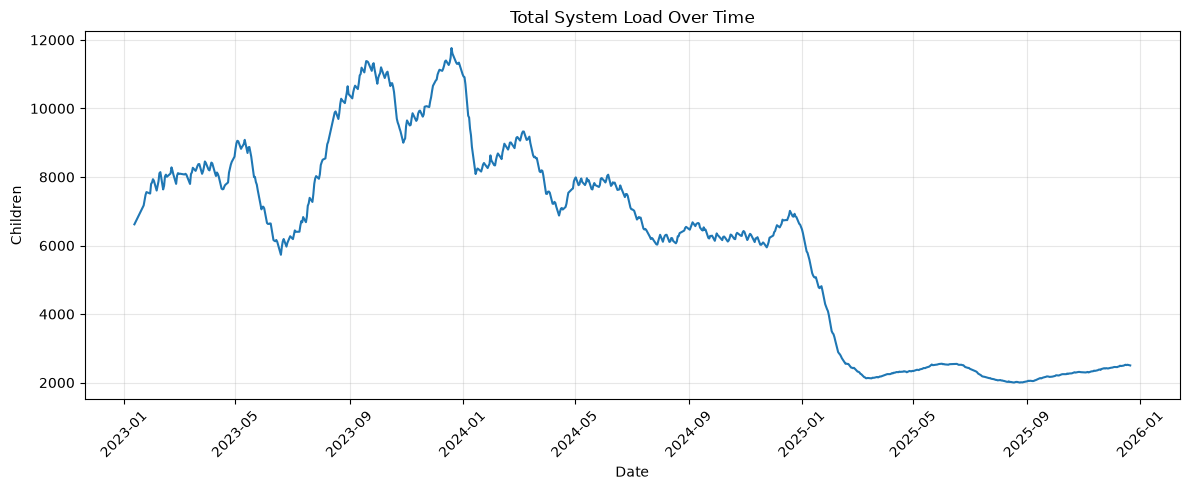

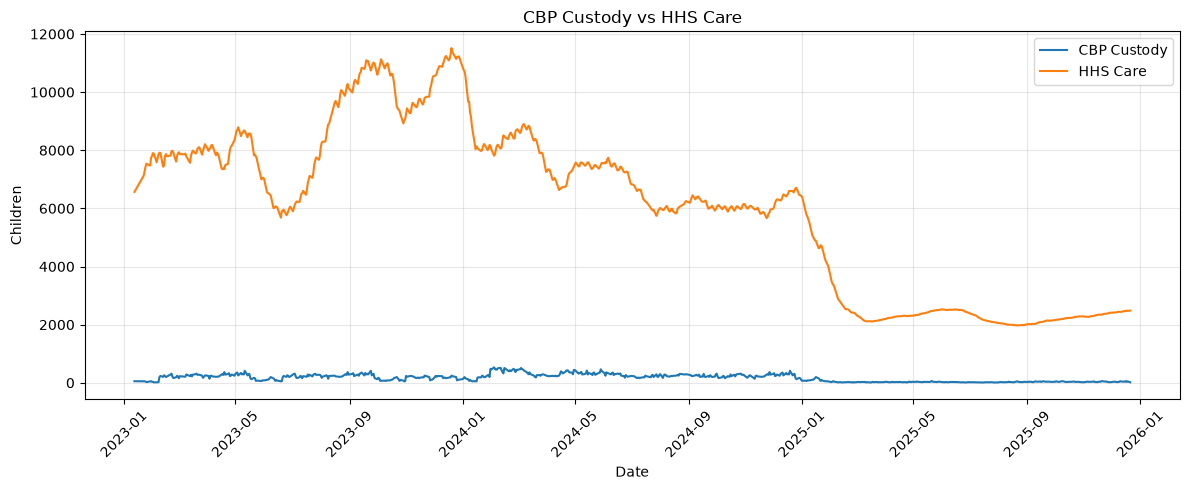

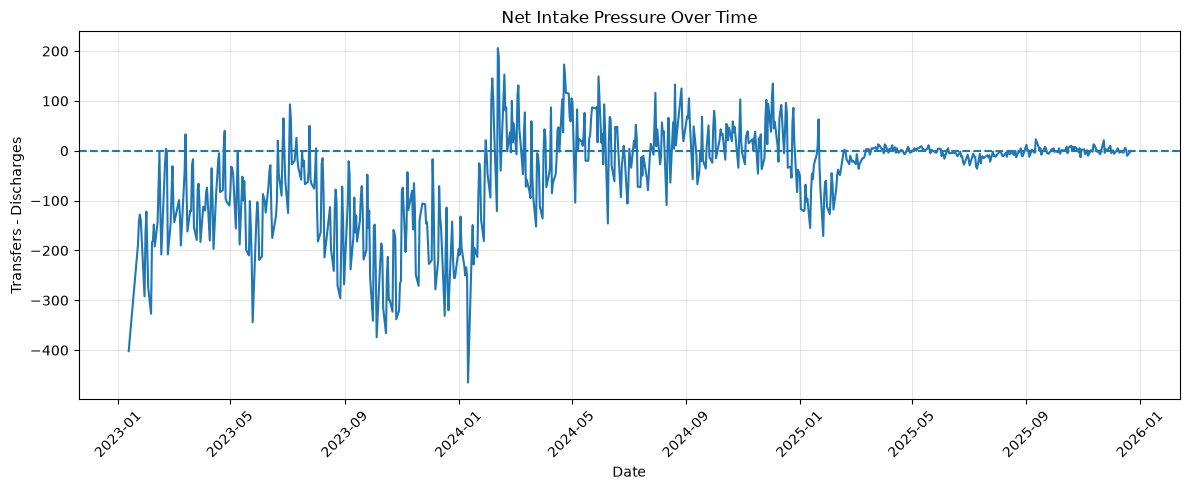

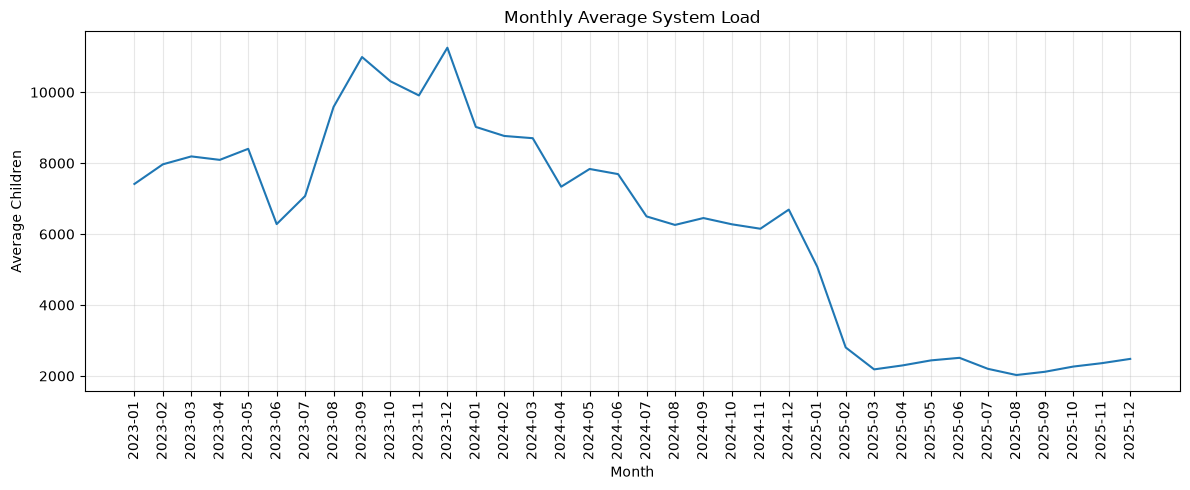

In [13]:
import matplotlib.pyplot as plt


# 1. Total System Load

plt.figure(figsize=(12, 5))

plt.plot(
    df["Date"],
    df["Total System Load"]
)

plt.title("Total System Load Over Time")
plt.xlabel("Date")
plt.ylabel("Children")

plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "../analysis/total_system_load.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 2. CBP vs HHS Load

plt.figure(figsize=(12, 5))

plt.plot(
    df["Date"],
    df["Children in CBP custody"],
    label="CBP Custody"
)

plt.plot(
    df["Date"],
    df["Children in HHS Care"],
    label="HHS Care"
)

plt.title("CBP Custody vs HHS Care")
plt.xlabel("Date")
plt.ylabel("Children")

plt.legend()
plt.grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "../analysis/cbp_vs_hhs_load.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 3. Net Intake Pressure

plt.figure(figsize=(12, 5))

plt.plot(
    df["Date"],
    df["Net Intake Pressure"]
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title("Net Intake Pressure Over Time")
plt.xlabel("Date")
plt.ylabel("Transfers - Discharges")

plt.grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "../analysis/net_intake_pressure.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 4. Monthly Average System Load

monthly_load = (
    df.groupby("Month")["Total System Load"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_load["Month"],
    monthly_load["Total System Load"]
)

plt.title("Monthly Average System Load")
plt.xlabel("Month")
plt.ylabel("Average Children")

plt.grid(True, alpha=0.3)

plt.xticks(
    rotation=90
)

plt.tight_layout()

plt.savefig(
    "../analysis/monthly_average_system_load.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()